Using a pretrained convolutional neural network model such as VGG16 or ResNet and fine-tune it to classify images into different categories such as animals or objects. The objective is to understand how pretrained models can be reused for new tasks with limited data. Use Intel Image Classification Dataset from Link:
https://www.kaggle.com/datasets/puneet6060/intel-image-classification

In [3]:
import os
import pandas as pd
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras import layers, Model

In [5]:
pip install kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [kagglehub]━ 1/2 [kagglehub]
Note: you may need to restart the kernel to use updated packages.


In [11]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("puneet6060/intel-image-classification")

print("Path to dataset files:", path)

Path to dataset files: /home/comp/.cache/kagglehub/datasets/puneet6060/intel-image-classification/versions/2


In [13]:
import os
import shutil
import random

SOURCE = r"/home/comp/.cache/kagglehub/datasets/puneet6060/intel-image-classification/versions/2"

# Find training folder
TRAIN = os.path.join(SOURCE, "seg_train", "seg_train")

# Save selected dataset in the same folder
DEST = os.path.join(SOURCE, "intel_6000")

classes = ["buildings", "forest", "glacier",
           "mountain", "sea", "street"]

random.seed(42)

for cls in classes:
    src = os.path.join(TRAIN, cls)
    dst = os.path.join(DEST, cls)
    os.makedirs(dst, exist_ok=True)

    images = random.sample(os.listdir(src), 1000)

    for img in images:
        shutil.copy2(
            os.path.join(src, img),
            os.path.join(dst, img)
        )

print("Done!")
print("6000 images saved at:")
print(DEST)

for cls in classes:
    print(cls, len(os.listdir(os.path.join(DEST, cls))))

Done!
6000 images saved at:
/home/comp/.cache/kagglehub/datasets/puneet6060/intel-image-classification/versions/2/intel_6000
buildings 1000
forest 1000
glacier 1000
mountain 1000
sea 1000
street 1000


In [17]:
import os
import numpy as np
import tensorflow as tf

DATASET = r"/home/comp/.cache/kagglehub/datasets/puneet6060/intel-image-classification/versions/2/intel_6000"

classes = ["buildings", "forest", "glacier",
           "mountain", "sea", "street"]

X = []
y = []

for label, cls in enumerate(classes):
    folder = os.path.join(DATASET, cls)

    for file in os.listdir(folder):
        path = os.path.join(folder, file)

        try:
            img = tf.keras.utils.load_img(
                path, target_size=(64, 64)
            )
            img = tf.keras.utils.img_to_array(img)

            X.append(img)
            y.append(label)
        except:
            pass

X = np.array(X, dtype=np.uint8)
y = np.array(y)

OUTPUT = r"/home/comp/.cache/kagglehub/datasets/puneet6060/intel-image-classification/versions/2/intel_6000"

np.savez_compressed(
    OUTPUT,
    images=X,
    labels=y,
    classes=np.array(classes)
)

print("Saved:", OUTPUT)
print("Images:", X.shape)
print("Labels:", y.shape)

Saved: /home/comp/.cache/kagglehub/datasets/puneet6060/intel-image-classification/versions/2/intel_6000
Images: (6000, 64, 64, 3)
Labels: (6000,)


In [19]:
import numpy as np
import pandas as pd

# Load dataset
FILE = r"/home/comp/.cache/kagglehub/datasets/puneet6060/intel-image-classification/versions/2/intel_6000.npz"

data = np.load(FILE)

X = data["images"]
y = data["labels"]
classes = data["classes"]

# Statistics
print("===== DATASET STATISTICS =====")
print("Number of images :", len(X))
print("Image shape      :", X.shape[1:])
print("Number of classes:", len(classes))
print("Classes          :", classes)
print("Data type        :", X.dtype)
print("Labels shape     :", y.shape)
print("Pixel range      :", X.min(), "to", X.max())

# Class distribution
counts = np.bincount(y)

stats = pd.DataFrame({
    "Class": classes,
    "Label": range(len(classes)),
    "Images": counts
})

print("\n===== CLASS DISTRIBUTION =====")
print(stats.to_string(index=False))

===== DATASET STATISTICS =====
Number of images : 6000
Image shape      : (64, 64, 3)
Number of classes: 6
Classes          : ['buildings' 'forest' 'glacier' 'mountain' 'sea' 'street']
Data type        : uint8
Labels shape     : (6000,)
Pixel range      : 0 to 255

===== CLASS DISTRIBUTION =====
    Class  Label  Images
buildings      0    1000
   forest      1    1000
  glacier      2    1000
 mountain      3    1000
      sea      4    1000
   street      5    1000


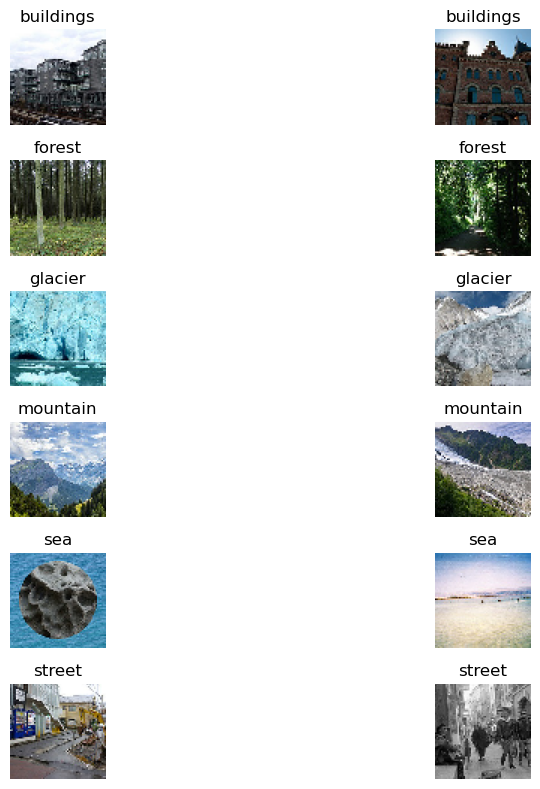

In [21]:
import matplotlib.pyplot as plt
# Display 2 images per class
plt.figure(figsize=(12, 8))

for label, cls in enumerate(classes):
    indexes = np.where(y == label)[0][:2]

    for j, idx in enumerate(indexes):
        position = label * 2 + j + 1
        plt.subplot(6, 2, position)
        plt.imshow(X[idx])
        plt.title(cls)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential, layers
from sklearn.model_selection import train_test_split

# Load data
FILE = r"C:\Users\admin\.cache\kagglehub\datasets\puneet6060\intel-image-classification\versions\2\intel_6000.npz"

data = np.load(FILE)
X = data["images"] / 255.0
y = data["labels"]
classes = data["classes"]

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# CNN
model = Sequential([
    layers.Input(shape=(64, 64, 3)),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(6, activation="softmax")
])

# Compile
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

# Test
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", accuracy)

Epoch 1/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.4651 - loss: 1.3098 - val_accuracy: 0.5531 - val_loss: 1.0814
Epoch 2/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.5883 - loss: 1.0313 - val_accuracy: 0.6531 - val_loss: 0.8887
Epoch 3/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.6602 - loss: 0.8976 - val_accuracy: 0.6875 - val_loss: 0.8236
Epoch 4/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.6982 - loss: 0.8261 - val_accuracy: 0.7281 - val_loss: 0.7342
Epoch 5/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.7284 - loss: 0.7469 - val_accuracy: 0.7240 - val_loss: 0.7247
Epoch 6/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.7505 - loss: 0.6779 - val_accuracy: 0.7458 - val_loss: 0.6883
Epoch 7/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.7779 - loss: 0.6184 - val_accuracy: 0.7625 - val_loss: 0.6281
Epoch 8/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.7935 - loss: 0.5668 - val_accu

In [23]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split

# Load data
FILE = r"C:\Users\admin\.cache\kagglehub\datasets\puneet6060\intel-image-classification\versions\2\intel_6000.npz"

data = np.load(FILE)
X = data["images"]
y = data["labels"]
classes = data["classes"]

# Resize images to VGG16 size
X = tf.image.resize(X, (224, 224))
X = preprocess_input(X)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X.numpy(), y, test_size=0.2, random_state=42, stratify=y
)

# Pretrained VGG16
base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze most layers, fine-tune last 4
base.trainable = True
for layer in base.layers[:-4]:
    layer.trainable = False

# Classifier
x = layers.GlobalAveragePooling2D()(base.output)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
output = layers.Dense(6, activation="softmax")(x)

model = Model(base.input, output)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train
model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=32,
    validation_split=0.2
)

# Test
loss, accuracy = model.evaluate(X_test, y_test)

print("VGG16 Test Accuracy:", accuracy)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/3
120/120 ━━━━━━━━━━━━━━━━━━━━ 267s 2s/step - accuracy: 0.5258 - loss: 1.4068 - val_accuracy: 0.7865 - val_loss: 0.6053
Epoch 2/3
120/120 ━━━━━━━━━━━━━━━━━━━━ 267s 2s/step - accuracy: 0.7724 - loss: 0.6403 - val_accuracy: 0.8365 - val_loss: 0.4338
Epoch 3/3
120/120 ━━━━━━━━━━━━━━━━━━━━ 267s 2s/step - accuracy: 0.8388 - loss: 0.4543 - val_accuracy: 0.8562 - val_loss: 0.3827
38/38 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.8675 - loss: 0.4040
VGG16 Test Accuracy: 0.8675000071525574


In [24]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split

# Load data
FILE = r"C:\Users\admin\.cache\kagglehub\datasets\puneet6060\intel-image-classification\versions\2\intel_6000.npz"

data = np.load(FILE)
X = data["images"]
y = data["labels"]

# Resize for ResNet50
X = tf.image.resize(X, (224, 224))
X = preprocess_input(X)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X.numpy(), y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Pretrained ResNet50
base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3) 
)

# Fine-tune last layers
base.trainable = True
for layer in base.layers[:-20]:
    layer.trainable = False

# Classifier
x = layers.GlobalAveragePooling2D()(base.output)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
output = layers.Dense(6, activation="softmax")(x)

model = Model(base.input, output)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train
model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=32,
    validation_split=0.2
)

# Test
loss, accuracy = model.evaluate(X_test, y_test)

print("ResNet50 Test Accuracy:", accuracy)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
Epoch 1/3
120/120 ━━━━━━━━━━━━━━━━━━━━ 162s 1s/step - accuracy: 0.4451 - loss: 1.4668 - val_accuracy: 0.7604 - val_loss: 0.7550
Epoch 2/3
120/120 ━━━━━━━━━━━━━━━━━━━━ 168s 1s/step - accuracy: 0.7763 - loss: 0.6727 - val_accuracy: 0.8469 - val_loss: 0.4622
Epoch 3/3
120/120 ━━━━━━━━━━━━━━━━━━━━ 153s 1s/step - accuracy: 0.8518 - loss: 0.4479 - val_accuracy: 0.8750 - val_loss: 0.3747
38/38 ━━━━━━━━━━━━━━━━━━━━ 35s 891ms/step - accuracy: 0.8867 - loss: 0.3429
ResNet50 Test Accuracy: 0.8866666555404663
